In [14]:
import os, glob, random
import numpy as np
import pandas as pd
import tensorflow as tf
import warnings
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

# Diagnostics: where is Python running, and what does it see?
home = os.path.expanduser("~")
desktop = os.path.join(home, "Desktop")
print("Home:", home)
print("Current working dir:", os.getcwd())
print("Desktop exists:", os.path.exists(desktop))
if os.path.exists(desktop):
    print("Desktop contents:", [repr(x) for x in os.listdir(desktop)])

# Search for the ground-truth CSV anywhere under your home folder
hits = glob.glob(os.path.join(home, "**", "MILK10k_Training_GroundTruth.csv"), recursive=True)
print("Found:", hits)

Home: /home/codespace
Current working dir: /workspaces/Explainable-Multimodal-AI-For-Skin-Cancer-Risk-Assessment
Desktop exists: False
Found: []


In [3]:
ID_COL = "lesion_id"
class_cols = list(gt.select_dtypes(include="number").columns)
gt["diagnosis"] = gt[class_cols].idxmax(axis=1)

paths = glob.glob(os.path.join(IMG_DIR, "**", "*.jp*g"), recursive=True)
imgs = pd.DataFrame({"path": paths})
imgs[ID_COL] = imgs["path"].apply(lambda p: os.path.basename(os.path.dirname(p)))

data = imgs.merge(gt[[ID_COL, "diagnosis"]], on=ID_COL, how="inner")
print("Images:", len(data), "| Lesions:", data[ID_COL].nunique())   # expect 10480 and 5240
print(data["diagnosis"].value_counts())

Images: 10480 | Lesions: 5240
diagnosis
BCC        5044
NV         1492
BKL        1088
SCCKA       946
MEL         900
AKIEC       606
DF          104
INF         100
VASC         94
BEN_OTH      88
MAL_OTH      18
Name: count, dtype: int64


In [4]:
from sklearn.model_selection import train_test_split

lesions = gt[[ID_COL, "diagnosis"]].drop_duplicates()

train_l, temp_l = train_test_split(
    lesions, test_size=0.30, stratify=lesions["diagnosis"], random_state=SEED)
val_l, test_l = train_test_split(
    temp_l, test_size=0.50, stratify=temp_l["diagnosis"], random_state=SEED)

split_map = {}
for name, part in [("train", train_l), ("val", val_l), ("test", test_l)]:
    for lid in part[ID_COL]:
        split_map[lid] = name

data["split"] = data[ID_COL].map(split_map)

print(pd.crosstab(data["diagnosis"], data["split"]))
data.to_csv(os.path.join(BASE, "image_table.csv"), index=False)

split      test  train  val
diagnosis                  
AKIEC        90    424   92
BCC         756   3530  758
BEN_OTH      14     62   12
BKL         162    762  164
DF           16     74   14
INF          16     70   14
MAL_OTH       2     12    4
MEL         136    630  134
NV          224   1044  224
SCCKA       142    662  142
VASC         14     66   14


In [5]:
meta2 = pd.read_csv(os.path.join(BASE, "MILK10k_Training_Metadata.csv"))
print(meta2.shape)
print(meta2.columns.tolist())
print(meta2.head())
print(meta2.isna().mean().round(3))

(10480, 17)
['lesion_id', 'image_type', 'isic_id', 'attribution', 'copyright_license', 'image_manipulation', 'age_approx', 'sex', 'skin_tone_class', 'site', 'MONET_ulceration_crust', 'MONET_hair', 'MONET_vasculature_vessels', 'MONET_erythema', 'MONET_pigmented', 'MONET_gel_water_drop_fluid_dermoscopy_liquid', 'MONET_skin_markings_pen_ink_purple_pen']
    lesion_id          image_type       isic_id      attribution  \
0  IL_0000652  clinical: close-up  ISIC_8149219  MILK study team   
1  IL_0000652         dermoscopic  ISIC_4671410  MILK study team   
2  IL_0003176  clinical: close-up  ISIC_3904045  MILK study team   
3  IL_0003176         dermoscopic  ISIC_5371928  MILK study team   
4  IL_0004688  clinical: close-up  ISIC_0791494  MILK study team   

  copyright_license image_manipulation  age_approx     sex  skin_tone_class  \
0          CC-BY-NC            altered        70.0    male                1   
1          CC-BY-NC    instrument only        70.0    male                1   
2

In [6]:
meta2 = pd.read_csv(os.path.join(BASE, "MILK10k_Training_Metadata.csv"))  # change to your actual filename

data = pd.read_csv(os.path.join(BASE, "image_table.csv"))
data["isic_id"] = data["path"].apply(lambda p: os.path.splitext(os.path.basename(p))[0])

keep = ["isic_id", "image_type", "age_approx", "sex", "skin_tone_class", "site"] + \
       [c for c in meta2.columns if c.startswith("MONET_")]
full = data.merge(meta2[keep], on="isic_id", how="left")

print("Rows:", len(full), "| matched:", full["image_type"].notna().sum())   # expect 10480 and 10480
print()
print("Missing fraction:")
print(full[["age_approx", "sex", "skin_tone_class", "site"]].isna().mean().round(3))
print()
print(full["image_type"].value_counts())
print()
print(pd.crosstab(full["skin_tone_class"], full["diagnosis"]))
print()
print(pd.crosstab(full["site"], full["split"]))
print()
print(full["sex"].value_counts(dropna=False))
print(full["age_approx"].describe())

full.to_csv(os.path.join(BASE, "image_table_full.csv"), index=False)

Rows: 10480 | matched: 10480

Missing fraction:
age_approx         0.004
sex                0.000
skin_tone_class    0.000
site               0.006
dtype: float64

image_type
clinical: close-up    5240
dermoscopic           5240
Name: count, dtype: int64

diagnosis        AKIEC   BCC  BEN_OTH  BKL  DF  INF  MAL_OTH  MEL   NV  SCCKA  \
skin_tone_class                                                                 
0                    0     2        0    0   0    6        0    0    4      0   
1                   38    38        4   48   8    4        2   32   32      2   
2                   42   154       22  118  18   10        6  242  370     10   
3                  404  3432       44  686  50   32       10  400  638    608   
4                   92   992       12  188  18   20        0  180  344    270   
5                   30   426        6   48  10   28        0   46  104     56   

diagnosis        VASC  
skin_tone_class        
0                   0  
1                   2  

In [7]:
full = pd.read_csv(os.path.join(BASE, "image_table_full.csv"))
MALIGNANT = ["AKIEC", "BCC", "MAL_OTH", "MEL", "SCCKA"]
full["malignant"] = full["diagnosis"].isin(MALIGNANT).astype(int)

# Sanity check: lesion-level fields should be identical across a lesion's two images
print(full.groupby("lesion_id")[["age_approx", "sex", "skin_tone_class", "site"]].nunique().max())
print()

les = full.groupby("lesion_id").agg(
    split=("split", "first"), diagnosis=("diagnosis", "first"),
    malignant=("malignant", "first"), age=("age_approx", "first"),
    sex=("sex", "first"), tone=("skin_tone_class", "first"), site=("site", "first"),
).reset_index()

les["tone_group"] = pd.cut(les["tone"], bins=[-1, 2, 3, 5], labels=["0-2", "3", "4-5"])
les["age_group"] = pd.cut(les["age"], bins=[0, 49, 64, 79, 120], labels=["<50", "50-64", "65-79", "80+"])

print("Lesions:", len(les), "| malignant fraction:", round(les["malignant"].mean(), 3))
print()

for col in ["sex", "tone_group", "age_group", "site"]:
    t = les.groupby([col, "split"], observed=True).agg(
        lesions=("malignant", "size"), malignant=("malignant", "sum")
    ).unstack("split").fillna(0).astype(int)
    print(t, "\n")

age_approx         1
sex                1
skin_tone_class    1
site               1
dtype: int64

Lesions: 5240 | malignant fraction: 0.717

       lesions            malignant           
split     test train  val      test train  val
sex                                           
female     302  1470  316       193   986  215
male       484  2198  470       370  1643  350 

           lesions            malignant           
split         test train  val      test train  val
tone_group                                        
0-2            103   406  108        45   193   46
3              441  2277  456       338  1739  350
4-5            242   985  222       180   697  169 

          lesions            malignant           
split        test train  val      test train  val
age_group                                        
<50           142   634  134        53   220   47
50-64         232  1064  211       169   791  156
65-79         296  1468  330       249  1188  274
80+           

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from sklearn.utils.class_weight import compute_class_weight

IMG_SIZE = 224
BATCH = 32

data = pd.read_csv(os.path.join(BASE, "image_table_full.csv"))

# Binary risk flag (edit this list if you decide AKIEC should not count as malignant)
MALIGNANT = ["AKIEC", "BCC", "MAL_OTH", "MEL", "SCCKA"]
data["malignant"] = data["diagnosis"].isin(MALIGNANT).astype(int)

train_df = data[data["split"] == "train"]
val_df = data[data["split"] == "val"]
test_df = data[data["split"] == "test"]

classes = sorted(data["diagnosis"].unique())   # fixed order used by every generator

def make_gen(df, augment, shuffle):
    aug = dict(rotation_range=20, horizontal_flip=True,
               vertical_flip=True, zoom_range=0.1) if augment else {}
    idg = ImageDataGenerator(preprocessing_function=preprocess_input, **aug)
    return idg.flow_from_dataframe(
        df, x_col="path", y_col="diagnosis", classes=classes,
        target_size=(IMG_SIZE, IMG_SIZE), batch_size=BATCH,
        class_mode="categorical", shuffle=shuffle, seed=SEED)

train_gen = make_gen(train_df, True, True)
val_gen = make_gen(val_df, False, False)
test_gen = make_gen(test_df, False, False)
print(train_gen.class_indices)

Found 7336 validated image filenames belonging to 11 classes.
Found 1572 validated image filenames belonging to 11 classes.
Found 1572 validated image filenames belonging to 11 classes.
{'AKIEC': 0, 'BCC': 1, 'BEN_OTH': 2, 'BKL': 3, 'DF': 4, 'INF': 5, 'MAL_OTH': 6, 'MEL': 7, 'NV': 8, 'SCCKA': 9, 'VASC': 10}


In [9]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.layers import Dense, Dropout, GlobalAveragePooling2D
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

# Softened class weights (square root) so the tiniest classes don't dominate training
cw = compute_class_weight("balanced", classes=np.arange(len(classes)), y=train_gen.classes)
class_weight = dict(enumerate(np.sqrt(cw)))

base_model = MobileNetV2(input_shape=(IMG_SIZE, IMG_SIZE, 3), include_top=False, weights="imagenet")
base_model.trainable = False

x = GlobalAveragePooling2D()(base_model.output)
x = Dropout(0.3)(x)
out = Dense(len(classes), activation="softmax")(x)
model = Model(base_model.input, out)

model.compile(optimizer=Adam(1e-3), loss="categorical_crossentropy", metrics=["accuracy"])

callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    ModelCheckpoint(os.path.join(BASE, "baseline_mobilenet.keras"),
                    monitor="val_loss", save_best_only=True),
]

history = model.fit(train_gen, validation_data=val_gen, epochs=15,
                    class_weight=class_weight, callbacks=callbacks)

Epoch 1/15
230/230 ━━━━━━━━━━━━━━━━━━━━ 68s 282ms/step - accuracy: 0.3718 - loss: 1.8797 - val_accuracy: 0.5407 - val_loss: 1.4381
Epoch 2/15
230/230 ━━━━━━━━━━━━━━━━━━━━ 70s 297ms/step - accuracy: 0.5210 - loss: 1.3897 - val_accuracy: 0.4319 - val_loss: 1.6018
Epoch 3/15
230/230 ━━━━━━━━━━━━━━━━━━━━ 69s 294ms/step - accuracy: 0.5254 - loss: 1.2936 - val_accuracy: 0.5941 - val_loss: 1.3002
Epoch 4/15
230/230 ━━━━━━━━━━━━━━━━━━━━ 66s 281ms/step - accuracy: 0.5626 - loss: 1.2324 - val_accuracy: 0.5293 - val_loss: 1.4269
Epoch 5/15
230/230 ━━━━━━━━━━━━━━━━━━━━ 68s 290ms/step - accuracy: 0.5746 - loss: 1.1878 - val_accuracy: 0.5712 - val_loss: 1.3587
Epoch 6/15
230/230 ━━━━━━━━━━━━━━━━━━━━ 69s 291ms/step - accuracy: 0.5901 - loss: 1.1299 - val_accuracy: 0.5089 - val_loss: 1.4681


In [16]:
# Unfreeze the top of MobileNetV2 and keep training gently
base_model.trainable = True
for layer in base_model.layers[:-30]:
    layer.trainable = False
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

model.compile(optimizer=Adam(3e-5), loss="categorical_crossentropy", metrics=["accuracy"])

callbacks_ft = [
    EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True),
    ModelCheckpoint(os.path.join(BASE, "baseline_mobilenet_finetuned.keras"),
                    monitor="val_loss", save_best_only=True),
]

history_ft = model.fit(train_gen, validation_data=val_gen, epochs=20,
                       class_weight=class_weight, callbacks=callbacks_ft)

Epoch 1/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 78s 324ms/step - accuracy: 0.5884 - loss: 1.1242 - val_accuracy: 0.5763 - val_loss: 1.3029
Epoch 2/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 75s 319ms/step - accuracy: 0.6205 - loss: 1.0264 - val_accuracy: 0.5458 - val_loss: 1.3797
Epoch 3/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 74s 317ms/step - accuracy: 0.6296 - loss: 1.0081 - val_accuracy: 0.5884 - val_loss: 1.2831
Epoch 4/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 75s 318ms/step - accuracy: 0.6430 - loss: 0.9700 - val_accuracy: 0.6011 - val_loss: 1.2279
Epoch 5/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 74s 316ms/step - accuracy: 0.6592 - loss: 0.9250 - val_accuracy: 0.5782 - val_loss: 1.1942
Epoch 6/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 74s 314ms/step - accuracy: 0.6611 - loss: 0.9062 - val_accuracy: 0.5598 - val_loss: 1.2878
Epoch 7/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 73s 314ms/step - accuracy: 0.6654 - loss: 0.8656 - val_accuracy: 0.5763 - val_loss: 1.2735
Epoch 8/20
230/230 ━━━━━━━━━━━━━━━━━━━━ 75s 319ms/step - accuracy: 0.6675 - loss: 0

In [17]:
val_df_r = val_df.reset_index(drop=True)
test_df_r = test_df.reset_index(drop=True)

probs_val = model.predict(val_gen)
probs_test = model.predict(test_gen)

50/50 ━━━━━━━━━━━━━━━━━━━━ 13s 258ms/step
50/50 ━━━━━━━━━━━━━━━━━━━━ 11s 212ms/step


Threshold chosen on validation: 0.427 

OVERALL (test)
                      0
n                   786
n_mal               563
sens   0.93 (0.91-0.95)
spec   0.52 (0.46-0.59)
auc    0.86 (0.83-0.89)
f1     0.88 (0.86-0.90)
brier  0.13 (0.12-0.14) 

                        n n_mal              sens              spec  \
sex=female            302   193  0.92 (0.88-0.96)  0.58 (0.49-0.66)   
sex=male              484   370  0.94 (0.91-0.96)  0.46 (0.37-0.55)   
tone_group=0-2        103    45  0.80 (0.67-0.90)  0.66 (0.54-0.78)   
tone_group=3          441   338  0.95 (0.93-0.97)  0.36 (0.27-0.45)   
tone_group=4-5        242   180  0.93 (0.89-0.96)  0.66 (0.55-0.78)   
age_group=<50         142    53  0.77 (0.67-0.89)  0.73 (0.64-0.82)   
age_group=50-64       232   169  0.92 (0.88-0.96)  0.48 (0.36-0.58)   
age_group=65-79       296   249  0.96 (0.93-0.98)  0.30 (0.18-0.42)   
age_group=80+         111    92  0.98 (0.94-1.00)  0.16 (0.00-0.34)   
site=head_neck_face   231   186  0.97 (0.

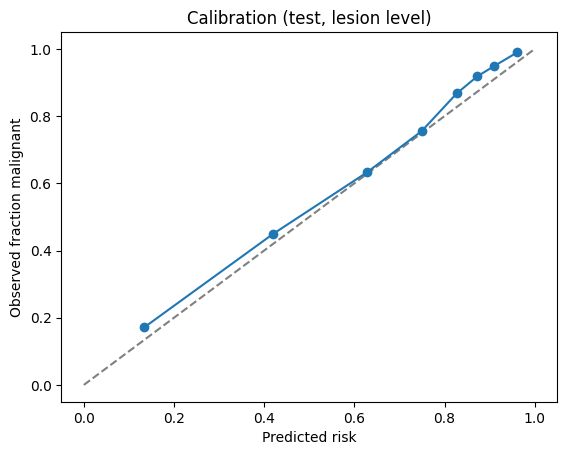

In [19]:
from sklearn.metrics import roc_auc_score, f1_score, brier_score_loss
from sklearn.calibration import calibration_curve

MAL_IDX = [classes.index(c) for c in MALIGNANT]

def lesion_table(df, probs):
    d = df[["lesion_id", "malignant", "sex", "skin_tone_class", "age_approx", "site"]].copy()
    d["risk"] = probs[:, MAL_IDX].sum(axis=1)          # P(malignant) per image
    les = d.groupby("lesion_id").agg(                  # average the two images per lesion
        risk=("risk", "mean"), malignant=("malignant", "first"), sex=("sex", "first"),
        tone=("skin_tone_class", "first"), age=("age_approx", "first"), site=("site", "first"),
    ).reset_index()
    les["tone_group"] = pd.cut(les["tone"], bins=[-1, 2, 3, 5], labels=["0-2", "3", "4-5"])
    les["age_group"] = pd.cut(les["age"], bins=[0, 49, 64, 79, 120], labels=["<50", "50-64", "65-79", "80+"])
    les["site"] = les["site"].fillna("unknown")
    small = les["site"].value_counts()[lambda s: s < 150].index
    les["site"] = les["site"].replace(list(small), "other")
    return les

def metrics(d, t):
    y, s = d["malignant"].values, d["risk"].values
    pred = (s >= t).astype(int)
    tp = ((pred == 1) & (y == 1)).sum(); fn = ((pred == 0) & (y == 1)).sum()
    tn = ((pred == 0) & (y == 0)).sum(); fp = ((pred == 1) & (y == 0)).sum()
    two = len(np.unique(y)) == 2
    return dict(sens=tp / (tp + fn) if tp + fn else np.nan,
                spec=tn / (tn + fp) if tn + fp else np.nan,
                auc=roc_auc_score(y, s) if two else np.nan,
                f1=f1_score(y, pred, zero_division=0),
                brier=brier_score_loss(y, s))

def report(d, t, n_boot=500):
    rng = np.random.default_rng(SEED)
    point = metrics(d, t)
    boots = pd.DataFrame([metrics(d.sample(len(d), replace=True,
                          random_state=int(rng.integers(1e9))), t) for _ in range(n_boot)])
    lo, hi = boots.quantile(0.025), boots.quantile(0.975)
    row = {"n": len(d), "n_mal": int(d["malignant"].sum())}
    for k in point:
        row[k] = f"{point[k]:.2f} ({lo[k]:.2f}-{hi[k]:.2f})"
    return row

def pick_threshold(d, target_sens=0.95):
    # highest cutoff that still catches >= 95% of malignant lesions, chosen on VALIDATION only
    best = 0.0
    for t in np.linspace(0, 1, 1001):
        sens = ((d["risk"] >= t) & (d["malignant"] == 1)).sum() / (d["malignant"] == 1).sum()
        if sens >= target_sens:
            best = t
    return best

val_les = lesion_table(val_df_r, probs_val)
test_les = lesion_table(test_df_r, probs_test)

T = pick_threshold(val_les)
print("Threshold chosen on validation:", round(T, 3), "\n")

print("OVERALL (test)")
print(pd.DataFrame([report(test_les, T)]).T, "\n")

rows = {}
for col in ["sex", "tone_group", "age_group", "site"]:
    for g, sub in test_les.groupby(col, observed=True):
        rows[f"{col}={g}"] = report(sub, T)
print(pd.DataFrame(rows).T)

# Calibration curve
frac, mean_pred = calibration_curve(test_les["malignant"], test_les["risk"], n_bins=8, strategy="quantile")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.plot(mean_pred, frac, marker="o")
plt.xlabel("Predicted risk"); plt.ylabel("Observed fraction malignant")
plt.title("Calibration (test, lesion level)")
plt.show()

In [20]:
np.save(os.path.join(BASE, "baseline_probs_val.npy"), probs_val)
np.save(os.path.join(BASE, "baseline_probs_test.npy"), probs_test)
val_les.to_csv(os.path.join(BASE, "baseline_val_lesions.csv"), index=False)
test_les.to_csv(os.path.join(BASE, "baseline_test_lesions.csv"), index=False)

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", None)

sub_tbl = pd.DataFrame(rows).T
sub_tbl.to_csv(os.path.join(BASE, "baseline_subgroups.csv"))
print(sub_tbl[["n", "n_mal", "auc", "sens", "spec"]])
print()

# Are age and skin tone overlapping? (test lesions)
print(pd.crosstab(test_les["tone_group"], test_les["age_group"]))
print()
print(test_les.groupby("tone_group", observed=True).agg(
    mean_age=("age", "mean"), malignant_fraction=("malignant", "mean")).round(2))

                        n n_mal               auc              sens              spec
sex=female            302   193  0.87 (0.83-0.91)  0.92 (0.88-0.96)  0.58 (0.49-0.66)
sex=male              484   370  0.85 (0.81-0.88)  0.94 (0.91-0.96)  0.46 (0.37-0.55)
tone_group=0-2        103    45  0.82 (0.73-0.89)  0.80 (0.67-0.90)  0.66 (0.54-0.78)
tone_group=3          441   338  0.82 (0.77-0.87)  0.95 (0.93-0.97)  0.36 (0.27-0.45)
tone_group=4-5        242   180  0.91 (0.86-0.94)  0.93 (0.89-0.96)  0.66 (0.55-0.78)
age_group=<50         142    53  0.84 (0.77-0.91)  0.77 (0.67-0.89)  0.73 (0.64-0.82)
age_group=50-64       232   169  0.85 (0.80-0.90)  0.92 (0.88-0.96)  0.48 (0.36-0.58)
age_group=65-79       296   249  0.79 (0.73-0.85)  0.96 (0.93-0.98)  0.30 (0.18-0.42)
age_group=80+         111    92  0.80 (0.70-0.89)  0.98 (0.94-1.00)  0.16 (0.00-0.34)
site=head_neck_face   231   186  0.83 (0.77-0.89)  0.97 (0.95-0.99)  0.33 (0.20-0.45)
site=lower_extremity  162   108  0.89 (0.83-0.94)  0.9

Brier before: 0.13
Brier after:  0.13
AUC (unchanged): 0.861


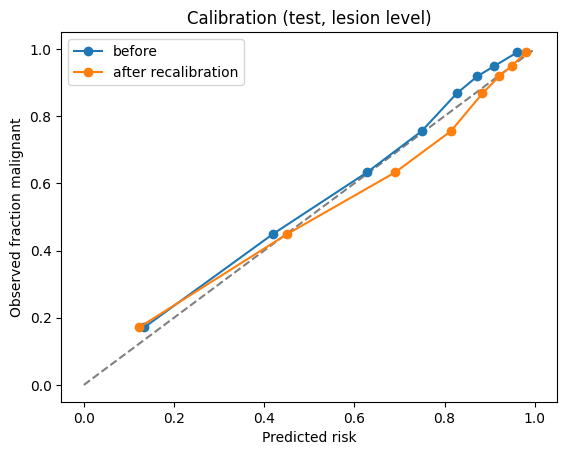

In [21]:
from sklearn.linear_model import LogisticRegression
from scipy.special import logit

def to_logit(r):
    r = np.clip(r, 1e-4, 1 - 1e-4)
    return logit(r).reshape(-1, 1)

platt = LogisticRegression(C=1e6)
platt.fit(to_logit(val_les["risk"].values), val_les["malignant"].values)
test_les["risk_cal"] = platt.predict_proba(to_logit(test_les["risk"].values))[:, 1]

print("Brier before:", round(brier_score_loss(test_les["malignant"], test_les["risk"]), 3))
print("Brier after: ", round(brier_score_loss(test_les["malignant"], test_les["risk_cal"]), 3))
print("AUC (unchanged):", round(roc_auc_score(test_les["malignant"], test_les["risk_cal"]), 3))

plt.plot([0, 1], [0, 1], "--", color="gray")
for col, lab in [("risk", "before"), ("risk_cal", "after recalibration")]:
    f, m = calibration_curve(test_les["malignant"], test_les[col], n_bins=8, strategy="quantile")
    plt.plot(m, f, marker="o", label=lab)
plt.xlabel("Predicted risk"); plt.ylabel("Observed fraction malignant")
plt.title("Calibration (test, lesion level)"); plt.legend()
plt.show()

In [19]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

meta_les = data.groupby("lesion_id").agg(
    split=("split", "first"), malignant=("malignant", "first"),
    age=("age_approx", "first"), sex=("sex", "first"), site=("site", "first"),
).reset_index()

num, cat = ["age"], ["sex", "site"]
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="unknown")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
])
clf = Pipeline([("prep", prep), ("lr", LogisticRegression(max_iter=1000))])

tr = meta_les[meta_les["split"] == "train"]
te = meta_les[meta_les["split"] == "test"]
clf.fit(tr[num + cat], tr["malignant"])
te = te.assign(risk=clf.predict_proba(te[num + cat])[:, 1])

print("Metadata-only AUC (test):", report(te[["malignant", "risk"]], 0.5)["auc"])

Metadata-only AUC (test): 0.74 (0.70-0.78)


In [24]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.metrics import roc_auc_score, f1_score, brier_score_loss
from sklearn.calibration import calibration_curve
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

SEED = 42
BASE = "/Users/govindasairam/Desktop/Skin Cancer"
IMG_SIZE = 224
MALIGNANT = ["AKIEC", "BCC", "MAL_OTH", "MEL", "SCCKA"]

# ---- tables saved earlier ----
data = pd.read_csv(os.path.join(BASE, "image_table_full.csv"))
data["malignant"] = data["diagnosis"].isin(MALIGNANT).astype(int)
val_les = pd.read_csv(os.path.join(BASE, "baseline_val_lesions.csv"))
test_les = pd.read_csv(os.path.join(BASE, "baseline_test_lesions.csv"))

# ---- lesion-level metadata (this is what was missing) ----
meta_les = data.groupby("lesion_id").agg(
    split=("split", "first"), malignant=("malignant", "first"),
    age=("age_approx", "first"), sex=("sex", "first"), site=("site", "first"),
).reset_index()

# ---- evaluation helpers ----
def metrics(d, t):
    y, s = d["malignant"].values, d["risk"].values
    pred = (s >= t).astype(int)
    tp = ((pred == 1) & (y == 1)).sum(); fn = ((pred == 0) & (y == 1)).sum()
    tn = ((pred == 0) & (y == 0)).sum(); fp = ((pred == 1) & (y == 0)).sum()
    two = len(np.unique(y)) == 2
    return dict(sens=tp / (tp + fn) if tp + fn else np.nan,
                spec=tn / (tn + fp) if tn + fp else np.nan,
                auc=roc_auc_score(y, s) if two else np.nan,
                f1=f1_score(y, pred, zero_division=0),
                brier=brier_score_loss(y, s))

def report(d, t, n_boot=500):
    rng = np.random.default_rng(SEED)
    point = metrics(d, t)
    boots = pd.DataFrame([metrics(d.sample(len(d), replace=True,
                          random_state=int(rng.integers(1e9))), t) for _ in range(n_boot)])
    lo, hi = boots.quantile(0.025), boots.quantile(0.975)
    row = {"n": len(d), "n_mal": int(d["malignant"].sum())}
    for k in point:
        row[k] = f"{point[k]:.2f} ({lo[k]:.2f}-{hi[k]:.2f})"
    return row

def pick_threshold(d, target_sens=0.95):
    best = 0.0
    for t in np.linspace(0, 1, 1001):
        sens = ((d["risk"] >= t) & (d["malignant"] == 1)).sum() / (d["malignant"] == 1).sum()
        if sens >= target_sens:
            best = t
    return best

# ---- metadata-only reference model (needed for the ROC figure) ----
num, cat = ["age"], ["sex", "site"]
prep = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num),
    ("cat", Pipeline([("imp", SimpleImputer(strategy="constant", fill_value="unknown")),
                      ("oh", OneHotEncoder(handle_unknown="ignore"))]), cat),
])
clf = Pipeline([("prep", prep), ("lr", LogisticRegression(max_iter=1000))])
tr = meta_les[meta_les["split"] == "train"]
te = meta_les[meta_les["split"] == "test"]
clf.fit(tr[num + cat], tr["malignant"])
te = te.assign(risk=clf.predict_proba(te[num + cat])[:, 1])

# ---- fine-tuned image model (needed for Grad-CAM) ----
classes = sorted(data["diagnosis"].unique())
MAL_IDX = [classes.index(c) for c in MALIGNANT]
model = tf.keras.models.load_model(os.path.join(BASE, "baseline_mobilenet_finetuned.keras"))

# ---- sanity checks ----
print("val / test lesions:", len(val_les), len(test_les))                      # expect 786 786
print("metadata-only AUC:", report(te[["malignant", "risk"]], 0.5)["auc"])     # expect about 0.74 (0.70-0.78)

val / test lesions: 786 786
metadata-only AUC: 0.74 (0.70-0.78)


Sites kept: ['trunk', 'head_neck_face', 'lower_extremity', 'upper_extremity']
Thresholds (95% sensitivity, from validation out-of-fold): 0.468 0.435

OVERALL (test)
             image only  image + metadata
n                   786               786
n_mal               563               563
sens   0.93 (0.91-0.95)  0.94 (0.92-0.96)
spec   0.52 (0.46-0.59)  0.49 (0.43-0.56)
auc    0.86 (0.83-0.89)  0.86 (0.83-0.89)
f1     0.88 (0.86-0.90)  0.88 (0.86-0.90)
brier  0.13 (0.11-0.15)  0.13 (0.11-0.14)

AUC gain (image+metadata minus image only): 0.003  95% CI (-0.002, 0.008)

SUBGROUPS: image only
                        n n_mal               auc              sens              spec
sex=female            302   193  0.87 (0.83-0.91)  0.92 (0.88-0.96)  0.58 (0.48-0.66)
sex=male              484   370  0.85 (0.81-0.88)  0.94 (0.91-0.96)  0.46 (0.37-0.55)
tone_group=0-2        103    45  0.82 (0.74-0.89)  0.80 (0.68-0.89)  0.66 (0.53-0.78)
tone_group=3          441   338  0.82 (0.77-0.87)  0.95 (

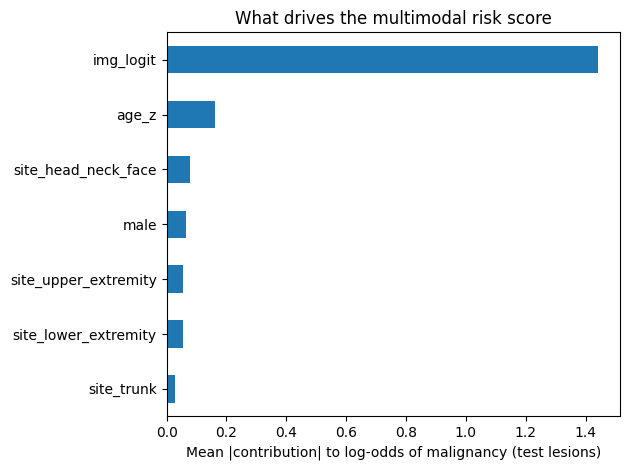

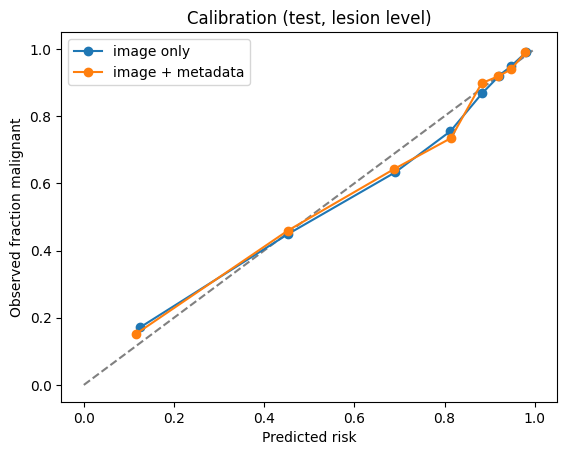

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from scipy.special import logit

# Site categories decided from TRAINING lesions only
trn = meta_les[meta_les["split"] == "train"]
age_med, age_mu, age_sd = trn["age"].median(), trn["age"].mean(), trn["age"].std()
site_counts = trn["site"].fillna("unknown").value_counts()
keep_sites = [s for s in site_counts.index if site_counts[s] >= 300 and s != "unknown"]
print("Sites kept:", keep_sites)

def design(les):
    m = les[["lesion_id", "risk"]].merge(
        meta_les[["lesion_id", "age", "sex", "site"]], on="lesion_id", how="left")
    s = m["site"].fillna("unknown")
    s = s.where(s.isin(keep_sites), "other")
    X = pd.DataFrame(index=m.index)
    X["img_logit"] = logit(np.clip(m["risk"].values, 1e-4, 1 - 1e-4))
    X["age_z"] = (m["age"].fillna(age_med) - age_mu) / age_sd
    X["male"] = (m["sex"] == "male").astype(int)
    for k in keep_sites:
        X["site_" + k] = (s == k).astype(int)
    return X

Xv, Xt = design(val_les), design(test_les)
yv = val_les["malignant"].values

def oof_threshold(X, y):
    p = cross_val_predict(LogisticRegression(max_iter=1000), X, y,
                          cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                          method="predict_proba")[:, 1]
    return pick_threshold(pd.DataFrame({"risk": p, "malignant": y}))

colsA = ["img_logit"]
lrA = LogisticRegression(max_iter=1000).fit(Xv[colsA], yv)
lrB = LogisticRegression(max_iter=1000).fit(Xv, yv)
TA, TB = oof_threshold(Xv[colsA], yv), oof_threshold(Xv, yv)
print("Thresholds (95% sensitivity, from validation out-of-fold):", round(TA, 3), round(TB, 3))

tA = test_les.copy(); tA["risk"] = lrA.predict_proba(Xt[colsA])[:, 1]
tB = test_les.copy(); tB["risk"] = lrB.predict_proba(Xt)[:, 1]

pd.set_option("display.width", 250); pd.set_option("display.max_columns", None)
print("\nOVERALL (test)")
print(pd.DataFrame({"image only": report(tA, TA), "image + metadata": report(tB, TB)}))

# Paired bootstrap of the AUC difference (same lesions, resampled together)
rng = np.random.default_rng(SEED)
y, sA, sB = tA["malignant"].values, tA["risk"].values, tB["risk"].values
diffs = []
for _ in range(1000):
    i = rng.integers(0, len(y), len(y))
    if y[i].min() == y[i].max():
        continue
    diffs.append(roc_auc_score(y[i], sB[i]) - roc_auc_score(y[i], sA[i]))
lo, hi = np.percentile(diffs, [2.5, 97.5])
print(f"\nAUC gain (image+metadata minus image only): {np.mean(diffs):.3f}  95% CI ({lo:.3f}, {hi:.3f})")

# Subgroups for both models
def sub_table(t, T):
    out = {}
    for col in ["sex", "tone_group", "age_group", "site"]:
        for g, sub in t.groupby(col, observed=True):
            out[f"{col}={g}"] = report(sub, T, n_boot=300)
    return pd.DataFrame(out).T[["n", "n_mal", "auc", "sens", "spec"]]

print("\nSUBGROUPS: image only"); print(sub_table(tA, TA))
print("\nSUBGROUPS: image + metadata"); print(sub_table(tB, TB))

# What the model uses: coefficients and per-feature contributions (log-odds)
coef = pd.Series(lrB.coef_[0], index=Xv.columns)
print("\n", pd.DataFrame({"coef (log-odds)": coef.round(2), "odds ratio": np.exp(coef).round(2)}))

contrib = (Xt - Xv.mean()) * coef
contrib.abs().mean().sort_values().plot(kind="barh")
plt.xlabel("Mean |contribution| to log-odds of malignancy (test lesions)")
plt.title("What drives the multimodal risk score")
plt.tight_layout(); plt.show()

# Calibration, both models
plt.plot([0, 1], [0, 1], "--", color="gray")
for d, lab in [(tA, "image only"), (tB, "image + metadata")]:
    f, m_ = calibration_curve(d["malignant"], d["risk"], n_bins=8, strategy="quantile")
    plt.plot(m_, f, marker="o", label=lab)
plt.xlabel("Predicted risk"); plt.ylabel("Observed fraction malignant")
plt.title("Calibration (test, lesion level)"); plt.legend(); plt.show()

tB.to_csv(os.path.join(BASE, "multimodal_test_lesions.csv"), index=False)

In [31]:
def quick_table(t, T):
    out = {}
    for col in ["sex", "tone_group", "age_group", "site"]:
        for g, sub in t.groupby(col, observed=True):
            m = metrics(sub, T)
            out[f"{col}={g}"] = {"n": len(sub), "auc": round(m["auc"], 3),
                                 "sens": round(m["sens"], 3), "spec": round(m["spec"], 3)}
    return pd.DataFrame(out).T

cmp = quick_table(tA, TA).join(quick_table(tB, TB), lsuffix="_img", rsuffix="_mm")
cmp = cmp.drop(columns="n_mm")
print(cmp.to_string())
cmp.to_csv(os.path.join(BASE, "fusion_subgroup_comparison.csv"))

print()
print(coef.round(2).to_string())
print("\ncorr(image logit, age):", round(np.corrcoef(Xt["img_logit"], Xt["age_z"])[0, 1], 2))

                      n_img  auc_img  sens_img  spec_img  auc_mm  sens_mm  spec_mm
sex=female            302.0    0.870     0.917     0.578   0.872    0.927    0.532
sex=male              484.0    0.848     0.938     0.465   0.855    0.954    0.456
tone_group=0-2        103.0    0.818     0.800     0.655   0.825    0.844    0.655
tone_group=3          441.0    0.820     0.950     0.359   0.826    0.962    0.350
tone_group=4-5        242.0    0.907     0.928     0.661   0.905    0.939    0.581
age_group=50-64       232.0    0.855     0.917     0.476   0.852    0.923    0.444
age_group=65-79       296.0    0.789     0.956     0.298   0.792    0.976    0.191
age_group=80+         111.0    0.799     0.978     0.158   0.787    1.000    0.105
age_group=<50         142.0    0.840     0.774     0.730   0.846    0.774    0.753
site=head_neck_face   231.0    0.830     0.973     0.333   0.837    0.978    0.289
site=lower_extremity  162.0    0.889     0.898     0.685   0.893    0.907    0.667
site

Malignant, high risk (correct) | BCC | risk 1.0
Benign, high risk (false alarm) | BKL | risk 0.94


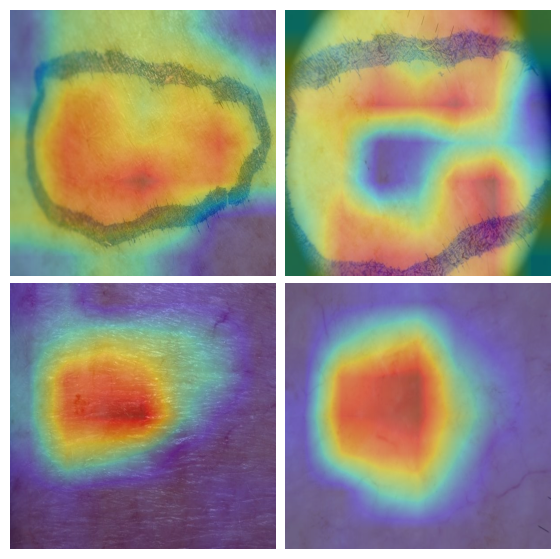

In [33]:
from PIL import Image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

FIG = os.path.join(BASE, "figures")
os.makedirs(FIG, exist_ok=True)
DISP = 512   # display resolution; the model still sees 224x224

def first(t):
    # a reloaded model can return a list holding one tensor; unwrap it
    return t[0] if isinstance(t, (list, tuple)) else t

grad_model = tf.keras.models.Model(
    first(model.input),
    [first(model.get_layer("out_relu").output), first(model.output)])

def gradcam(path):
    full = Image.open(path).convert("RGB")
    x = preprocess_input(np.array(full.resize((IMG_SIZE, IMG_SIZE)), dtype="float32"))[None, ...]
    with tf.GradientTape() as tape:
        conv, preds = grad_model(x, training=False)
        score = tf.reduce_sum(tf.gather(preds, MAL_IDX, axis=1))   # P(malignant)
    grads = tape.gradient(score, conv)
    w = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(w * conv, axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    cam = np.array(Image.fromarray((cam * 255).astype("uint8")).resize(
        (DISP, DISP), Image.BILINEAR)) / 255.0
    return np.array(full.resize((DISP, DISP), Image.LANCZOS)), cam

diag = data.groupby("lesion_id")["diagnosis"].first().reset_index()
t = test_les.merge(diag, on="lesion_id")

picks = {
    "Malignant, high risk (correct)":  t[t.malignant == 1].sort_values("risk", ascending=False).iloc[0],
    "Benign, high risk (false alarm)": t[t.malignant == 0].sort_values("risk", ascending=False).iloc[0],
}

# Poster version: two lesions, clinical (left) and dermoscopic (right), no titles
fig, axes = plt.subplots(2, 2, figsize=(7, 7))
for r, (title, row) in enumerate(picks.items()):
    les_imgs = data[data["lesion_id"] == row["lesion_id"]]
    for c, itype in enumerate(["clinical: close-up", "dermoscopic"]):
        p = les_imgs.loc[les_imgs["image_type"] == itype, "path"].iloc[0]
        img, cam = gradcam(p)
        ax = axes[r, c]
        ax.imshow(img); ax.imshow(cam, cmap="jet", alpha=0.4); ax.axis("off")
    print(title, "|", row["diagnosis"], "| risk", round(row["risk"], 2))
plt.subplots_adjust(wspace=0.03, hspace=0.03)
plt.savefig(os.path.join(FIG, "fig5_gradcam.png"), dpi=300, bbox_inches="tight", pad_inches=0.02)
plt.show()

In [23]:
from scipy.stats import spearmanr

art_cols = ["MONET_hair",
            "MONET_gel_water_drop_fluid_dermoscopy_liquid",
            "MONET_skin_markings_pen_ink_purple_pen"]
short = lambda c: c.replace("MONET_", "")[:14]

# 1) Do the artifact scores flag what we saw in the four example lesions?
for title, row in picks.items():
    print(title)
    print(data.loc[data["lesion_id"] == row["lesion_id"], ["image_type"] + art_cols]
          .rename(columns=short).round(2).to_string(index=False), "\n")

# 2) Does the model's risk track the artifacts?
d = test_df_r.copy()
d["risk_img"] = probs_test[:, MAL_IDX].sum(axis=1)

rows = []
for c in art_cols:
    mal, ben = d["malignant"] == 1, d["malignant"] == 0
    rows.append({
        "artifact": short(c),
        "corr with true label (all data)": round(spearmanr(data[c], data["malignant"])[0], 2),
        "corr with model risk (test)": round(spearmanr(d[c], d["risk_img"])[0], 2),
        "within malignant": round(spearmanr(d.loc[mal, c], d.loc[mal, "risk_img"])[0], 2),
        "within benign": round(spearmanr(d.loc[ben, c], d.loc[ben, "risk_img"])[0], 2),
    })
print(pd.DataFrame(rows).to_string(index=False))

# 3) Performance by tercile of the pen-marking score
c = "MONET_skin_markings_pen_ink_purple_pen"
d["pen_group"] = pd.qcut(d[c], 3, labels=["low", "mid", "high"])
print()
for g, sub in d.groupby("pen_group", observed=True):
    print(f"pen marking {g:>4}: n={len(sub):4d}  malignant={sub['malignant'].mean():.2f}  "
          f"mean risk={sub['risk_img'].mean():.2f}  "
          f"AUC={roc_auc_score(sub['malignant'], sub['risk_img']):.3f}")

# 4) Does the image score track age even within the same true class?
print()
for lab in [0, 1]:
    m = (test_les["malignant"].values == lab)
    r = np.corrcoef(Xt["img_logit"].values[m], Xt["age_z"].values[m])[0, 1]
    print(f"corr(image logit, age) within malignant={lab}: {r:.2f}")

Malignant, high risk (correct)
        image_type  hair  gel_water_drop  skin_markings_
clinical: close-up  0.18            0.17            0.94
       dermoscopic  0.20            0.21            0.50 

Benign, low risk (correct)
        image_type  hair  gel_water_drop  skin_markings_
       dermoscopic  0.21            0.31            0.55
clinical: close-up  0.26            0.11            0.23 

Malignant, low risk (missed)
        image_type  hair  gel_water_drop  skin_markings_
clinical: close-up  0.27            0.22            0.43
       dermoscopic  0.39            0.53            0.38 

Benign, high risk (false alarm)
        image_type  hair  gel_water_drop  skin_markings_
clinical: close-up  0.10            0.18            0.02
       dermoscopic  0.34            0.40            0.14 

      artifact  corr with true label (all data)  corr with model risk (test)  within malignant  within benign
          hair                            -0.07                        -0.04   

In [34]:
from scipy.special import logit
from scipy.stats import spearmanr

c = "MONET_skin_markings_pen_ink_purple_pen"
d = test_df_r.copy()
d["risk_img"] = probs_test[:, MAL_IDX].sum(axis=1)
d["risk_logit"] = logit(np.clip(d["risk_img"], 1e-4, 1 - 1e-4))

# 1) all three pen-marking groups side by side
d["pen_group"] = pd.qcut(d[c], 3, labels=["low", "mid", "high"])
rows = []
for g, sub in d.groupby("pen_group", observed=True):
    rows.append({"pen marking": g, "n": len(sub),
                 "malignant frac": round(sub["malignant"].mean(), 2),
                 "mean risk": round(sub["risk_img"].mean(), 2),
                 "AUC": round(roc_auc_score(sub["malignant"], sub["risk_img"]), 3)})
print(pd.DataFrame(rows).to_string(index=False))

# 2) correlation between pen score and model risk WITHIN each diagnosis
rows = []
for dx, sub in d.groupby("diagnosis"):
    if len(sub) >= 40:
        rows.append({"diagnosis": dx, "n": len(sub),
                     "corr(pen, risk)": round(spearmanr(sub[c], sub["risk_logit"])[0], 2)})
print()
print(pd.DataFrame(rows).to_string(index=False))

# 3) one summary number after removing diagnosis-level differences
pen_c = d[c] - d.groupby("diagnosis")[c].transform("mean")
risk_c = d["risk_logit"] - d.groupby("diagnosis")["risk_logit"].transform("mean")
print("\nwithin-diagnosis corr(pen marking, model risk):", round(spearmanr(pen_c, risk_c)[0], 2))

pen marking   n  malignant frac  mean risk   AUC
        low 524            0.81       0.76 0.797
        mid 524            0.75       0.71 0.810
       high 524            0.59       0.60 0.850

diagnosis   n  corr(pen, risk)
    AKIEC  90             0.02
      BCC 756             0.15
      BKL 162            -0.04
      MEL 136             0.04
       NV 224            -0.14
    SCCKA 142            -0.11

within-diagnosis corr(pen marking, model risk): 0.04


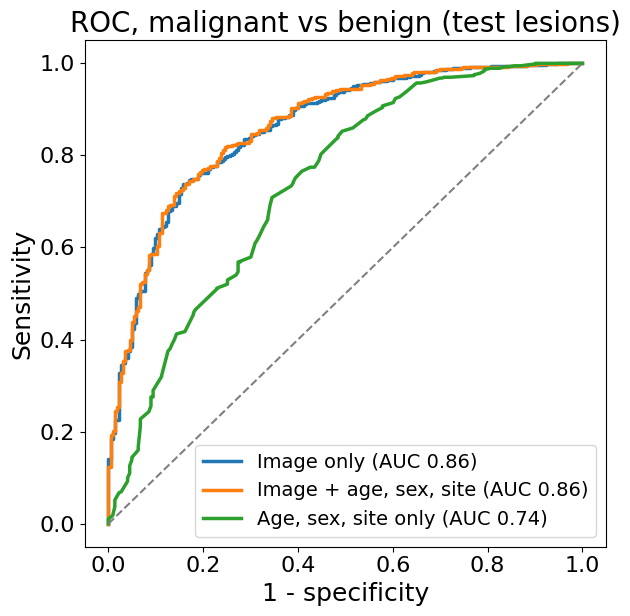

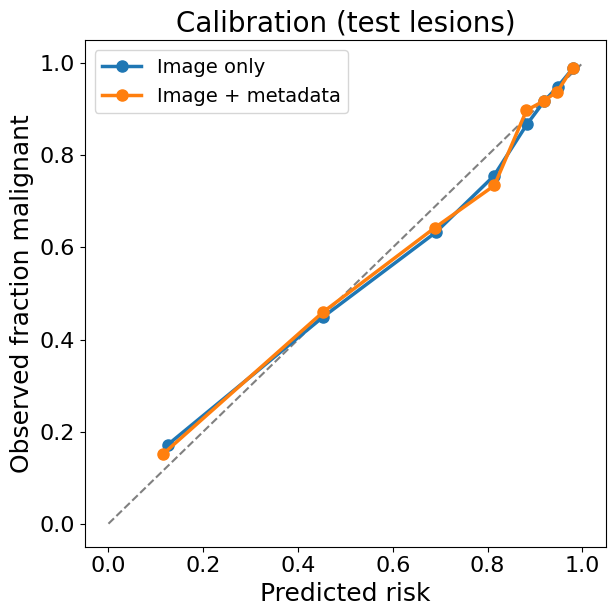

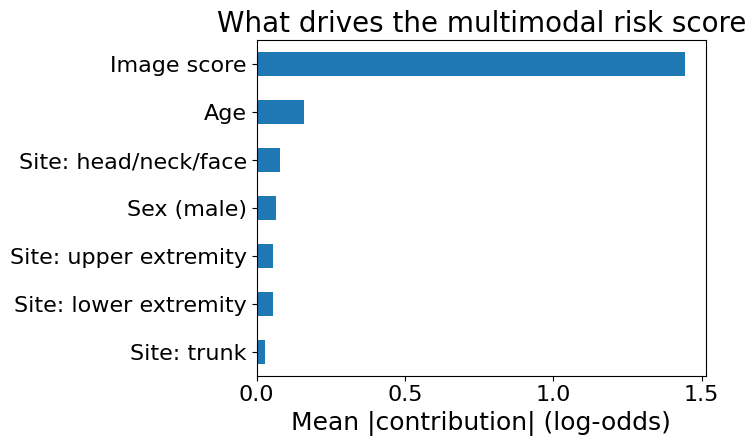

Saved to: /Users/govindasairam/Desktop/Skin Cancer/figures


In [35]:
plt.rcParams.update({"font.size": 18, "axes.titlesize": 20, "axes.labelsize": 18,
                     "legend.fontsize": 14, "xtick.labelsize": 16, "ytick.labelsize": 16})

import os
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.calibration import calibration_curve

FIG = os.path.join(BASE, "figures")
os.makedirs(FIG, exist_ok=True)

# Figure 1: ROC curves for the three models (same 786 test lesions)
plt.figure(figsize=(6.5, 6.5))
for df_, lab in [(tA, "Image only"), (tB, "Image + age, sex, site"), (te, "Age, sex, site only")]:
    fpr, tpr, _ = roc_curve(df_["malignant"], df_["risk"])
    auc_ = roc_auc_score(df_["malignant"], df_["risk"])
    plt.plot(fpr, tpr, linewidth=2.5, label=f"{lab} (AUC {auc_:.2f})")
plt.plot([0, 1], [0, 1], "--", color="gray")
plt.xlabel("1 - specificity"); plt.ylabel("Sensitivity")
plt.title("ROC, malignant vs benign (test lesions)")
plt.legend(loc="lower right"); plt.tight_layout()
plt.savefig(os.path.join(FIG, "fig1_roc.png"), dpi=300); plt.show()

# Figure 2: calibration
plt.figure(figsize=(6.5, 6.5))
plt.plot([0, 1], [0, 1], "--", color="gray")
for df_, lab in [(tA, "Image only"), (tB, "Image + metadata")]:
    f_, m_ = calibration_curve(df_["malignant"], df_["risk"], n_bins=8, strategy="quantile")
    plt.plot(m_, f_, marker="o", markersize=8, linewidth=2.5, label=lab)
plt.xlabel("Predicted risk"); plt.ylabel("Observed fraction malignant")
plt.title("Calibration (test lesions)"); plt.legend(); plt.tight_layout()
plt.savefig(os.path.join(FIG, "fig2_calibration.png"), dpi=300); plt.show()

# Figure 4: what drives the multimodal score
# (Figure 3, the subgroup plot, is skipped: it was redrawn separately for the poster.)
names = {"img_logit": "Image score", "age_z": "Age", "male": "Sex (male)",
         "site_trunk": "Site: trunk", "site_head_neck_face": "Site: head/neck/face",
         "site_lower_extremity": "Site: lower extremity", "site_upper_extremity": "Site: upper extremity"}
imp = contrib.abs().mean().sort_values().rename(index=names)
plt.figure(figsize=(7.5, 4.8))
imp.plot(kind="barh")
plt.xlabel("Mean |contribution| (log-odds)")
plt.title("What drives the multimodal risk score"); plt.tight_layout()
plt.savefig(os.path.join(FIG, "fig4_contributions.png"), dpi=300); plt.show()

print("Saved to:", FIG)

In [36]:
print({k: (k in globals()) for k in ["model", "data", "test_les", "MAL_IDX", "IMG_SIZE", "BASE"]})

{'model': True, 'data': True, 'test_les': True, 'MAL_IDX': True, 'IMG_SIZE': True, 'BASE': True}


Malignant, high risk (correct) | BCC | risk 1.0
     /Users/govindasairam/Desktop/Skin Cancer/MILK10k_Training_Input/MILK10k_Training_Input/IL_0836583/ISIC_6037847.jpg
     /Users/govindasairam/Desktop/Skin Cancer/MILK10k_Training_Input/MILK10k_Training_Input/IL_0836583/ISIC_2088803.jpg
Benign, high risk (false alarm) | BKL | risk 0.94
     /Users/govindasairam/Desktop/Skin Cancer/MILK10k_Training_Input/MILK10k_Training_Input/IL_9565203/ISIC_9676478.jpg
     /Users/govindasairam/Desktop/Skin Cancer/MILK10k_Training_Input/MILK10k_Training_Input/IL_9565203/ISIC_7238849.jpg


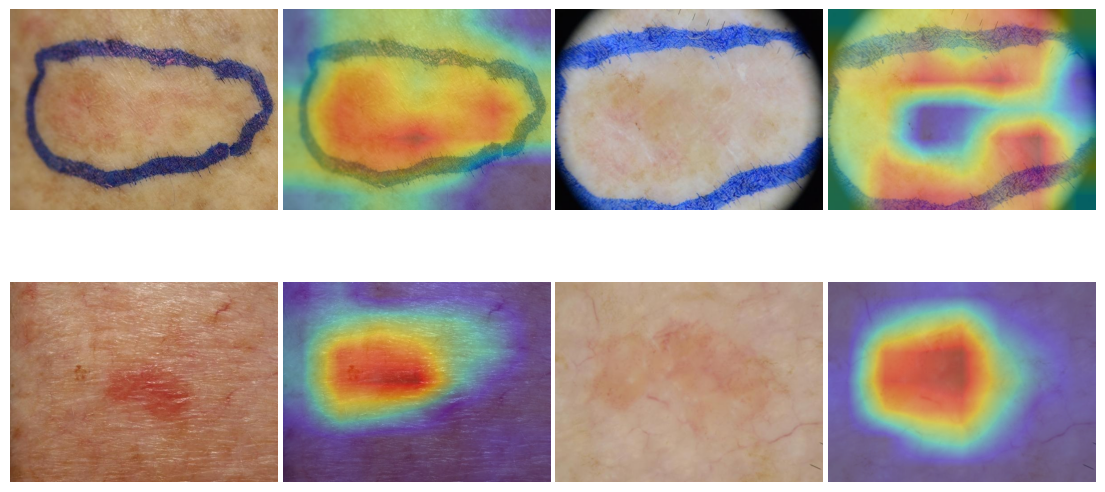

In [37]:
from PIL import Image
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

FIG = os.path.join(BASE, "figures")
os.makedirs(FIG, exist_ok=True)
MAXSIDE = 1100   # longest side of each displayed panel, in pixels

def first(t):
    return t[0] if isinstance(t, (list, tuple)) else t

grad_model = tf.keras.models.Model(
    first(model.input),
    [first(model.get_layer("out_relu").output), first(model.output)])

def gradcam(path):
    full = Image.open(path).convert("RGB")                       # raw dataset photo
    x = preprocess_input(np.array(full.resize((IMG_SIZE, IMG_SIZE)), dtype="float32"))[None, ...]
    with tf.GradientTape() as tape:
        conv, preds = grad_model(x, training=False)
        score = tf.reduce_sum(tf.gather(preds, MAL_IDX, axis=1))  # P(malignant)
    grads = tape.gradient(score, conv)
    w = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)
    cam = tf.nn.relu(tf.reduce_sum(w * conv, axis=-1))[0].numpy()
    cam = cam / (cam.max() + 1e-8)
    scale = min(1.0, MAXSIDE / max(full.size))
    disp = full.resize((round(full.width * scale), round(full.height * scale)), Image.LANCZOS)
    cam_img = Image.fromarray((cam * 255).astype("uint8")).resize(disp.size, Image.BILINEAR)
    return np.array(disp), np.array(cam_img) / 255.0

diag = data.groupby("lesion_id")["diagnosis"].first().reset_index()
t = test_les.merge(diag, on="lesion_id")
picks = {
    "Malignant, high risk (correct)":  t[t.malignant == 1].sort_values("risk", ascending=False).iloc[0],
    "Benign, high risk (false alarm)": t[t.malignant == 0].sort_values("risk", ascending=False).iloc[0],
}

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for r, (title, row) in enumerate(picks.items()):
    les_imgs = data[data["lesion_id"] == row["lesion_id"]]
    used = []
    for c, itype in enumerate(["clinical: close-up", "dermoscopic"]):
        p = les_imgs.loc[les_imgs["image_type"] == itype, "path"].iloc[0]
        used.append(p)
        img, cam = gradcam(p)
        a_orig, a_model = axes[r, 2 * c], axes[r, 2 * c + 1]
        a_orig.imshow(img); a_orig.axis("off")
        a_model.imshow(img); a_model.imshow(cam, cmap="jet", alpha=0.4); a_model.axis("off")
    print(title, "|", row["diagnosis"], "| risk", round(row["risk"], 2))
    for p in used:
        print("    ", p)
plt.subplots_adjust(wspace=0.02, hspace=0.02)
plt.savefig(os.path.join(FIG, "fig4_gradcam_compare.png"), dpi=300, bbox_inches="tight", pad_inches=0.02)
plt.show()